# Halo – cosmic-web cross-correlation

The measurement of the paper on one halo mass bin: the isotropic 1D-WCCF and the 3D-WCCF in the local tidal eigenframe, for every web type, for the whole bin and for its early- / late-forming tails (top / bottom 20% in $z_{\rm f}$), with jackknife errors.

For the web cells $c$ of type $W$ (weights $w_c=(1+\delta_c)_+$) and halos $h$,

$$\hat\xi_{\rm Wh}(B)=\frac{1}{\bar n_h V_B}\,\frac{\sum_{c\in W}w_c\,N_h(c,B)}{\sum_{c\in W}w_c}-1,$$

with $B$ a spherical shell (1D) or a bin in the folded eigenframe coordinates $r_i=|(\mathbf{x}_h-\mathbf{x}_c)\cdot\mathbf{e}_i(\mathbf{x}_c)|$, $V_B=8\,\Delta r_1\Delta r_2\Delta r_3$ (3D).

In [12]:
import sys
from pathlib import Path
import pywccf

import numpy as np
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
plt.style.use('default')

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 15, 'axes.titlesize': 14, 'legend.fontsize': 12,
    'axes.linewidth': 1.6, 'legend.frameon': False,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6, 'ytick.major.size': 6, 'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'xtick.major.width': 1.3, 'ytick.major.width': 1.3,
})

def grid(*axes):
    """Major-tick grid only (line plots)."""
    for ax in axes:
        ax.grid(True, which='major', alpha=0.25, lw=0.7)
        ax.grid(False, which='minor')

def top_legend(fig, handles, labels, ncol=None):
    """Figure legend above the panels, in one row."""
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 1.0),
               ncol=ncol or len(labels), frameon=False)

print('pywccf', pywccf.__version__)

pywccf 0.2.0


In [18]:
# print time and peak RSS

import time, threading
from contextlib import contextmanager
import psutil

@contextmanager
def track(log, key, dt=0.05):
    """Wall time and peak RSS (process, sampled every dt s) of the block -> log[key]."""
    proc = psutil.Process()
    rss0 = proc.memory_info().rss
    peak, stop = [rss0], threading.Event()
    def sample():
        while not stop.wait(dt):
            peak[0] = max(peak[0], proc.memory_info().rss)
    th = threading.Thread(target=sample, daemon=True); th.start()
    t0 = time.perf_counter()
    try:
        yield
    finally:
        t = time.perf_counter() - t0
        stop.set(); th.join()
        peak[0] = max(peak[0], proc.memory_info().rss)
        log[key] = dict(time_s=t, peak_rss_gb=peak[0] / 2**30, delta_gb=(peak[0] - rss0) / 2**30)

def print_perf(log):
    print(f"\n{'step':14s} {'time [s]':>9s} {'peak RSS [GB]':>14s} {'increase [GB]':>14s}")
    for k, v in log.items():
        print(f"{k:14s} {v['time_s']:9.1f} {v['peak_rss_gb']:14.2f} {v['delta_gb']:14.2f}")

## 1. Inputs

In [ ]:
from pywccf import TidalField, HaloSample, WCCF1D, WCCF3D, WEB_TYPES, save_results, load_results
from pywccf.core import PAPER_EDGES

INPUT_DIR = Path('/Volumes/T7/Simulation/ELUCID')

FIELD_FILE = INPUT_DIR / 'field_099.2.hdf5'       # R_s = 2, lambda_th = 0
HALO_FILE  = INPUT_DIR / 'halo_0701.hdf5'
MASS_BIN   = (11.5, 12.0)                              # log(M_h / h^-1 Msun)
TAIL       = 0.2                                       # old / young = top / bottom 20% in z_f
OUT        = Path('output'); OUT.mkdir(exist_ok=True)

tf = TidalField.from_file(FIELD_FILE, load_evec='lazy')
halos = HaloSample.from_file(HALO_FILE, l_box=tf.l_box).select_paper()
matter = None
edges = PAPER_EDGES                                  # 17 bins incl. the underflow bin [0, 0.5)
MAX_CELLS, WORKERS = 1_000_000, 8

print(tf)
print('volume fractions:', {k: round(v, 3) for k, v in tf.volume_fractions().items()})

field file: /Volumes/T7/Simulation/ELUCID/field_099.2.hdf5
  delta_sm_x: (500, 500, 500), float64
  density: (500, 500, 500), float32
  evec: (500, 500, 500, 3, 3), float32
  header: (), object
  l_box: (), float64
  lam: (500, 500, 500, 3), float32
  lambda_th: (), float64
  n_grids: (), int64
  smoothing_scale: (), float64
[TidalField] Mesh(n_grids=500, l_box=500), keys=('lam', 'delta')
[TidalField] R_s=2.0, lambda_th=0, void=0.134, sheet=0.538, filament=0.308, knot=0.019
halo file: /Volumes/T7/Simulation/ELUCID/halo_0701.hdf5
  FileNr: (1450186,), int32
  GroupIndex: (1450186,), int32
  M_exit: (1450186,), float32
  M_exit_code: (1450186,), int32
  R200m: (1450186,), float32
  SubMostBoundID: (1450186,), int64
  SubhaloIndex: (1450186,), int32
  V200: (1450186,), float32
  Vmax: (1450186,), float32
  backsplash: (1450186,), int8
  concentration: (1450186,), float32
  exit_snap: (1450186,), int32
  is_backsplash: (1450186,), int8
  lambda: (1450186,), float32
  mass: (1450186,), floa

## 2. Halo samples

In [8]:
halos = halos.subset_by_val('mass', lo=MASS_BIN[0], hi=MASS_BIN[1])
young, old = halos.quantile_masks('zf', TAIL)
samples = {'all': np.ones(len(halos), bool), 'old': old, 'young': young}
print(f'{len(halos):,} halos in [{MASS_BIN[0]}, {MASS_BIN[1]}): {old.sum():,} old, {young.sum():,} young')
print(f"median z_f: old {np.median(halos['zf'][old]):.2f}, young {np.median(halos['zf'][young]):.2f}; "
      f"mean log M_h: old {halos['mass'][old].mean():.3f}, young {halos['mass'][young].mean():.3f}")

737,065 halos in [11.5, 12.0): 147,414 old, 147,411 young
median z_f: old 2.08, young 0.71; mean log M_h: old 11.694, young 11.722


## 3. Measurement

One estimator object per dimension; each `compute(web, samples)` does a single pair-counting pass for all three samples. Errors: delete-one jackknife over $4^3$ sub-cubes of web cells (`'bootstrap'` and `'none'` are also available; the central value is always the deterministic estimator).

!!! Warning
`'bootstrap'` would underestimate the uncertainty. Please use `'jackknife'` .

In [ ]:
kw = dict(edges=edges, max_cells=MAX_CELLS, workers=WORKERS, verbose=False)
w1 = WCCF1D(tf, halos, **kw)          # PH estimator in spherical shells
w3 = WCCF3D(tf, halos, **kw)          # PH estimator in the eigenframe (numba kernel if available)

res1, res3, perf = {}, {}, {}
with track(perf, 'total'):
    for web in WEB_TYPES:
        print(f'\nComputing {web} WCCF ...')
        with track(perf, f'{web}/1d'):
            res1[web] = w1.compute(web, samples, error='jackknife', n_jk_side=4)
        with track(perf, f'{web}/3d'):
            res3[web] = w3.compute(web, samples, error='jackknife', n_jk_side=4)
        c = w3.cells(web)
        print(f'{web:9s} {c.n:>9,} of {c.n_total:,} cells')

print_perf(perf)
res3['filament']['all']


Computing void WCCF ...


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


void      1,000,000 of 16,778,109 cells

Computing sheet WCCF ...
sheet     1,000,000 of 67,291,144 cells

Computing filament WCCF ...
filament  1,000,000 of 38,542,460 cells

Computing knot WCCF ...
knot      1,000,000 of 2,388,287 cells

step            time [s]  peak RSS [GB]  increase [GB]
void/1d             29.0           1.55           1.51
void/3d             13.2           1.59           1.38
sheet/1d            36.9           1.92           1.40
sheet/3d            11.3           1.80           1.36
filament/1d         41.5           1.86           1.43
filament/3d         12.4           1.86           1.24
knot/1d             43.0           1.77           1.41
knot/3d             12.1           1.85           1.34
total              199.3           1.90           1.86


WCCFResult(3D, web='filament', name='all', method='ph', error='jackknife', shape=(17, 17, 17))

## 4. Directional slices $\xi_{\rm 3D}(r_i)$

`profile(i)` varies $r_i$ with the other two coordinates in their innermost bin (as in the paper); the isotropic $\xi_{\rm 1D}(r)$ is shown for reference. The underflow bin is not drawn.

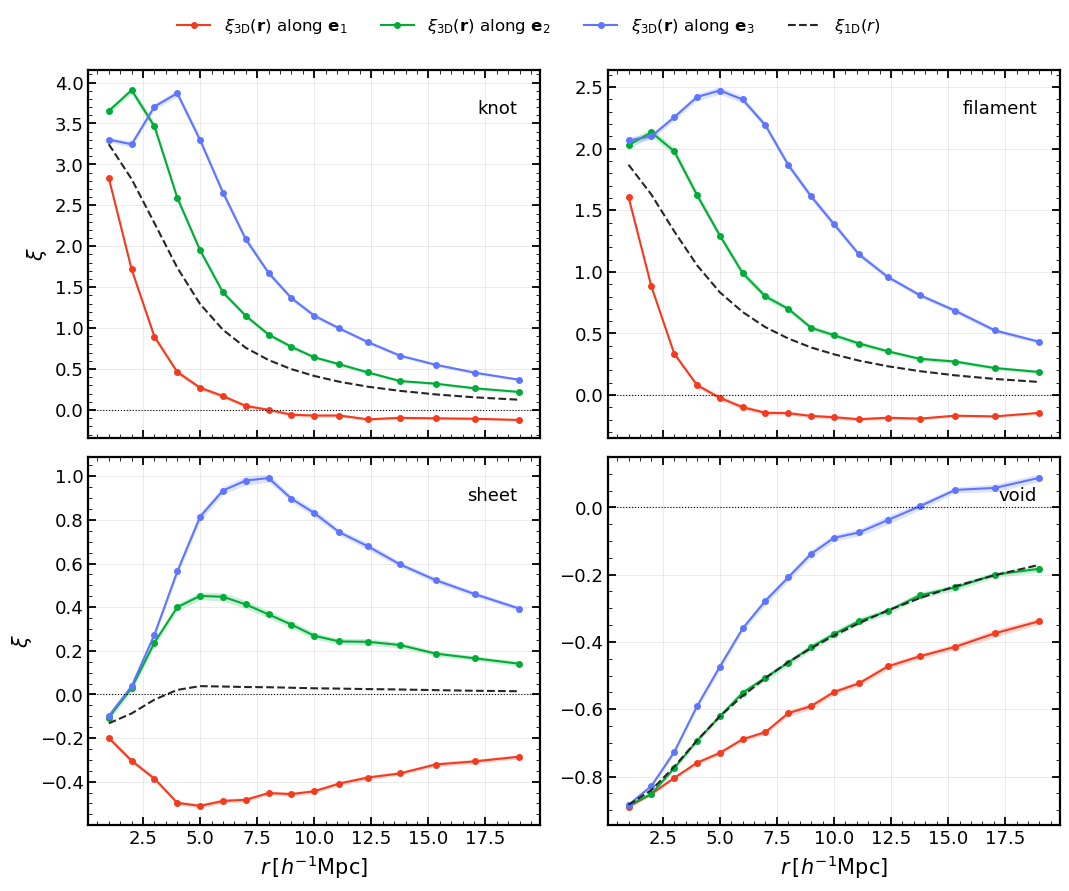

In [13]:
COL = {1: '#f33b1f', 2: '#00ac38', 3: '#5e76ff'}
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True)
for ax, web in zip(axs.flat, WEB_TYPES[::-1]):
    for i in (1, 2, 3):
        r, xi, sd = res3[web]['all'].profile(i)
        ax.plot(r[1:], xi[1:], color=COL[i], marker='o', ms=4)
        ax.fill_between(r[1:], (xi - sd)[1:], (xi + sd)[1:], color=COL[i], alpha=0.2, lw=0)
    r1 = res1[web]['all']
    ax.plot(r1.r[1:], r1.xi[1:], color='0.15', ls='--')
    ax.axhline(0, color='k', lw=0.8, ls=':')
    ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
    grid(ax)
for ax in axs[1]:
    ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$\xi$')
fig.tight_layout()
handles = [plt.Line2D([], [], color=COL[i], marker='o', ms=4) for i in (1, 2, 3)] + [plt.Line2D([], [], color='0.15', ls='--')]
top_legend(fig, handles, [rf'$\xi_{{\rm 3D}}(\mathbf{{r}})$ along $\mathbf{{e}}_{i}$' for i in (1, 2, 3)] + [r'$\xi_{\rm 1D}(r)$'])

## 5. Morphology: orthogonal sections of $\xi_{\rm 3D}(\mathbf{r})$
The statistic is measured in the first octant; the panels mirror it into four quadrants for display only (third coordinate in its innermost bin).

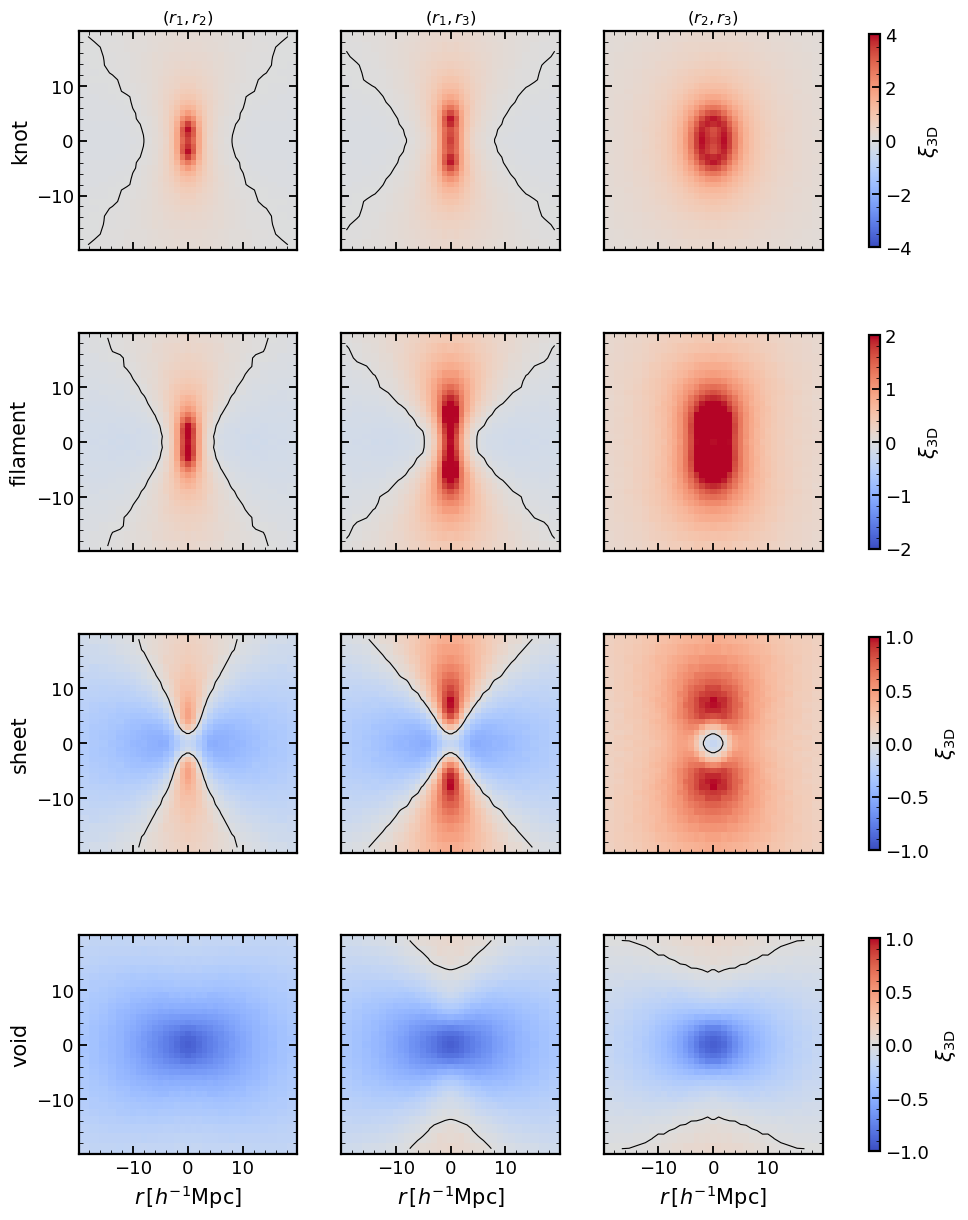

In [14]:
def mirrored(ra, rb, z):
    ra2 = np.concatenate([-ra[::-1], ra]); rb2 = np.concatenate([-rb[::-1], rb])
    z2 = np.block([[z[::-1, ::-1], z[::-1, :]], [z[:, ::-1], z]])
    return ra2, rb2, z2

planes = [(1, 2), (1, 3), (2, 3)]
fig, axs = plt.subplots(4, 3, figsize=(12, 15), sharex=True, sharey=True)
for row, web in zip(axs, WEB_TYPES[::-1]):
    lim = {'knot': 4, 'filament': 2, 'sheet': 1, 'void': 1}[web]
    for ax, (a, b) in zip(row, planes):
        ra, rb, z = res3[web]['all'].plane((a, b))
        X, Y, Z = mirrored(ra, rb, z)
        im = ax.pcolormesh(X, Y, Z.T, cmap='coolwarm', vmin=-lim, vmax=lim, shading='nearest')
        ax.contour(X, Y, Z.T, levels=[0], colors='k', linewidths=0.8)
        ax.set_aspect('equal')
    for ax, (a, b) in zip(row, planes):
        ax.set_title(rf'$(r_{a}, r_{b})$', fontsize=12) if web == 'knot' else None
    row[0].set_ylabel(web)
    fig.colorbar(im, ax=row, shrink=0.85, label=r'$\xi_{\rm 3D}$')
for ax in axs[-1]:
    ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')

## 6. Halo age: amplitude ratio $A_W(\mathbf{r})=\xi^{\rm old}_{\rm Wh}/\xi^{\rm young}_{\rm Wh}$

Unstable where $\xi^{\rm young}\to0$; points with $|\xi^{\rm young}|<2\sigma$ are masked. The error is the delete-one jackknife of the ratio itself: both tails were measured in one pass with the same regions, so `samples` of the two results are paired and their covariance is kept.

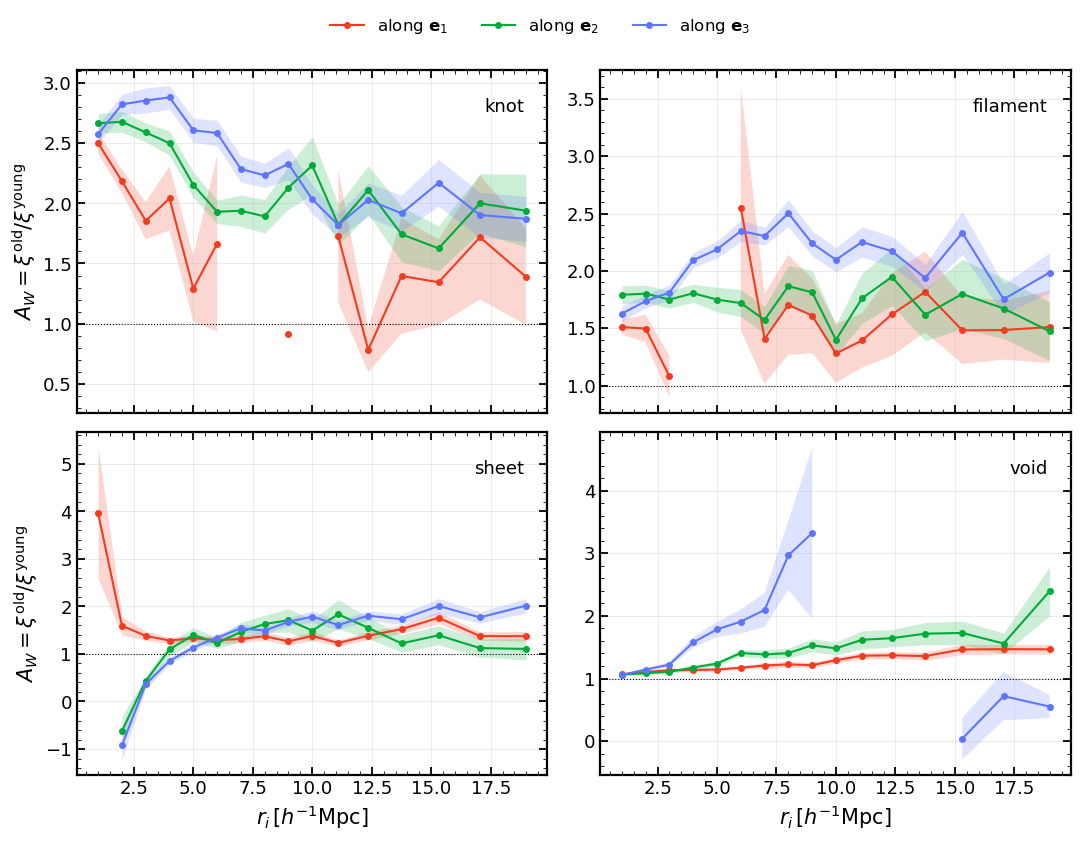

In [15]:
def ratio_profile(web, i, snr=2.0):
    o, y = res3[web]['old'], res3[web]['young']
    r, xo, _ = o.profile(i)
    _, xy, sy = y.profile(i)
    sl = [0, 0, 0]; sl[i - 1] = slice(None)
    sl = (slice(None),) + tuple(sl)
    A_jk = o.samples[sl] / y.samples[sl]
    n = len(A_jk)
    sd = np.sqrt((n - 1) / n * ((A_jk - A_jk.mean(0)) ** 2).sum(0))
    bad = np.abs(xy) < snr * sy
    return r, np.where(bad, np.nan, xo / xy), np.where(bad, np.nan, sd)

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, web in zip(axs.flat, WEB_TYPES[::-1]):
    for i in (1, 2, 3):
        r, A, sd = ratio_profile(web, i)
        ax.plot(r[1:], A[1:], color=COL[i], marker='o', ms=4)
        ax.fill_between(r[1:], (A - sd)[1:], (A + sd)[1:], color=COL[i], alpha=0.2, lw=0)
    ax.axhline(1, color='k', lw=0.8, ls=':')
    ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
    grid(ax)
for ax in axs[1]:
    ax.set_xlabel(r'$r_i\,[h^{-1}{\rm Mpc}]$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$A_W=\xi^{\rm old}/\xi^{\rm young}$')
fig.tight_layout()
top_legend(fig, [plt.Line2D([], [], color=COL[i], marker='o', ms=4) for i in (1, 2, 3)],
           [rf'along $\mathbf{{e}}_{i}$' for i in (1, 2, 3)])

## 7. Halo–web $\xi_{\rm 1D}$: pair counts (PH) vs. CIC + FFT

The same halo–web correlation by two algorithms. **PH**: pair counts of halos around each web cell in spherical shells (the estimator of §3). **CIC + FFT** (`method='fft'`): the halos are assigned to the tidal mesh with CIC, the web-cell weight field is convolved with the halo overdensity by FFT, and the result is averaged over the grid displacements of each shell. The two agree beyond a few cell sizes; below that the CIC smoothing suppresses the FFT one. Note that the FFT route uses all web cells, PH a random subset of `MAX_CELLS`. Both without errors here, so the timings compare the estimators themselves.


step            time [s]  peak RSS [GB]  increase [GB]
void/ph             38.8           1.50           1.45
void/fft            33.3           4.68           4.41
sheet/ph            56.3           1.73           1.59
sheet/fft           58.3           5.35           3.63
filament/ph         66.4           1.81           1.67
filament/fft        40.1           4.94           4.40
knot/ph             61.2           1.85           1.71
knot/fft            37.5           4.35           2.63
total/ph           222.6           1.85           1.71
total/fft          169.3           5.35           4.41


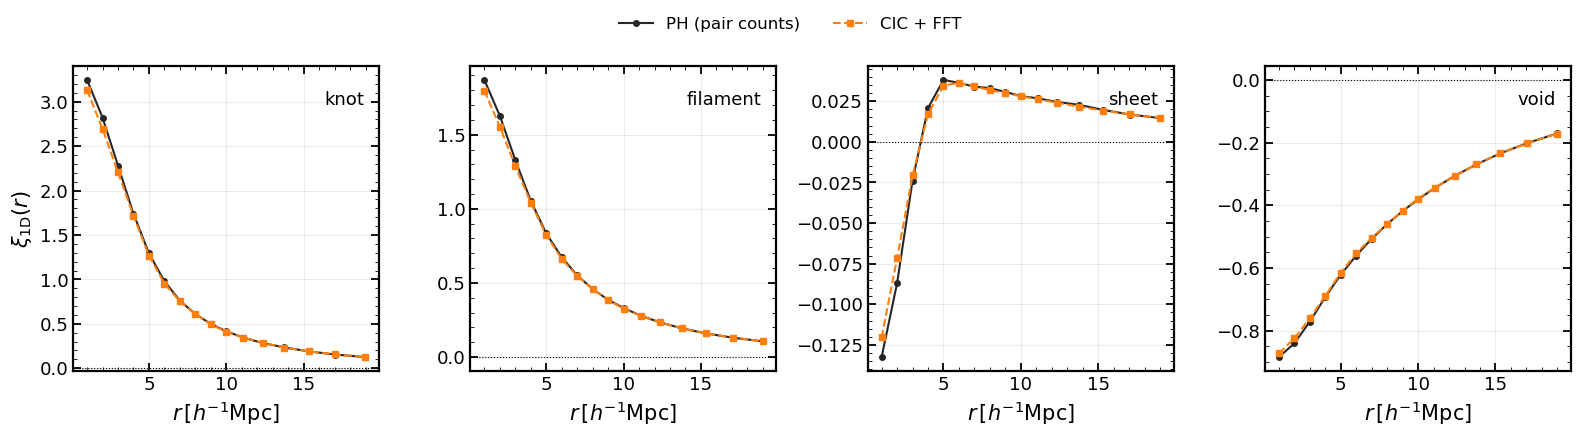

In [20]:
w1_ph  = WCCF1D(tf, halos, edges=edges, method='ph', verbose=False)                      # PH estimator
w1_fft = WCCF1D(tf, halos, edges=edges, method='fft', scheme='cic', verbose=False)  # halos via CIC + FFT

res_ph, res_fft, perf_alg = {}, {}, {}
for web in WEB_TYPES:
    with track(perf_alg, f'{web}/ph'):
        res_ph[web] = w1_ph.compute(web, samples, error='none')
    with track(perf_alg, f'{web}/fft'):
        res_fft[web] = w1_fft.compute(web, samples, error='none')
for alg in ('ph', 'fft'):
    ks = [k for k in perf_alg if k.endswith(f'/{alg}')]
    perf_alg[f'total/{alg}'] = dict(
        time_s=sum(perf_alg[k]['time_s'] for k in ks), 
        peak_rss_gb=max(perf_alg[k]['peak_rss_gb'] for k in ks), 
        delta_gb=max(perf_alg[k]['delta_gb'] for k in ks)
        )
print_perf(perf_alg)

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, web in zip(axs, WEB_TYPES[::-1]):
    p, f = res_ph[web]['all'], res_fft[web]['all']
    ax.plot(p.r[1:], p.xi[1:], 'o-', color='0.15', ms=4)
    ax.plot(f.r[1:], f.xi[1:], 's--', color='C1', ms=4)
    ax.axhline(0, color='k', lw=0.8, ls=':')
    ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
    ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')
    grid(ax)
axs[0].set_ylabel(r'$\xi_{\rm 1D}(r)$')
fig.tight_layout()
top_legend(fig, axs[0].lines[:2], ['PH (pair counts)', 'CIC + FFT'])

## 8. Save and reload

In [21]:
path = OUT / (f'halo_web_m{MASS_BIN[0]}_{MASS_BIN[1]}.h5')
results = {web: {f'1d_{k}': v for k, v in res1[web].items()} | {f'3d_{k}': v for k, v in res3[web].items()}
           for web in WEB_TYPES}
save_results(
    path, results, 
    run_info={'mass_bin': list(MASS_BIN), 'tail': TAIL, 'R_s': tf.R_s,'lambda_th': tf.lam_th, })
back = load_results(path)
print(path, '|', sorted(back['filament']), '|', back['run'])
r, xi, sd = back['filament']['3d_old'].profile(3)
print('filament, old, xi_3D along e3:', xi[1:5].round(3))

output/halo_web_m11.5_12.0.h5 | ['1d_all', '1d_old', '1d_young', '3d_all', '3d_old', '3d_young'] | {'R_s': 2.0, 'lambda_th': 0.0, 'mass_bin': array([11.5, 12. ]), 'tail': 0.2}
filament, old, xi_3D along e3: [2.643 2.774 3.086 3.424]
